LaTeX rendering: ON
grid 140x140 | n = 5748 LAND cells | T = 12410 days (34 yr)
land cells per box: A Mekong 906 | B Mindanao 126 | C Pen. Malaysia 384 | D Java 176

season = 5 months PER CELL | onset: May 30% Apr 30% Mar 17% Feb 13% Nov 3% Jan 2%
>> shortest consecutive run covering 90% of cells: Jan-Feb-Mar-Apr-May = 91.9%
   A Mekong         season = Apr-May-Jun-Jul-Aug
   B Mindanao       season = Apr-May-Jun-Jul-Aug
   C Pen. Malaysia  season = Mar-Apr-May-Jun-Jul
   D Java           season = Jan-Feb-Mar-Apr-May

q90 Tw_x: mean 28.71 degC | 257117 events (1.32/cell/yr) | D 4.26 d | 5.60 d/cell/yr | 3.67% of in-season days

--- SENSITIVITY to season length NM ---
 NM   q90 Tw  ev/cell/yr  d/cell/yr      D  %light  %heavy  90% run
  3    28.87        0.74       3.04   4.11    19.8    20.5      5 mo
  4    28.79        1.02       4.27   4.18    19.8    20.7      5 mo
  5    28.71        1.32       5.60   4.26    19.5    20.9      5 mo
  6    28.65        1.61       6.97   4.32    19.

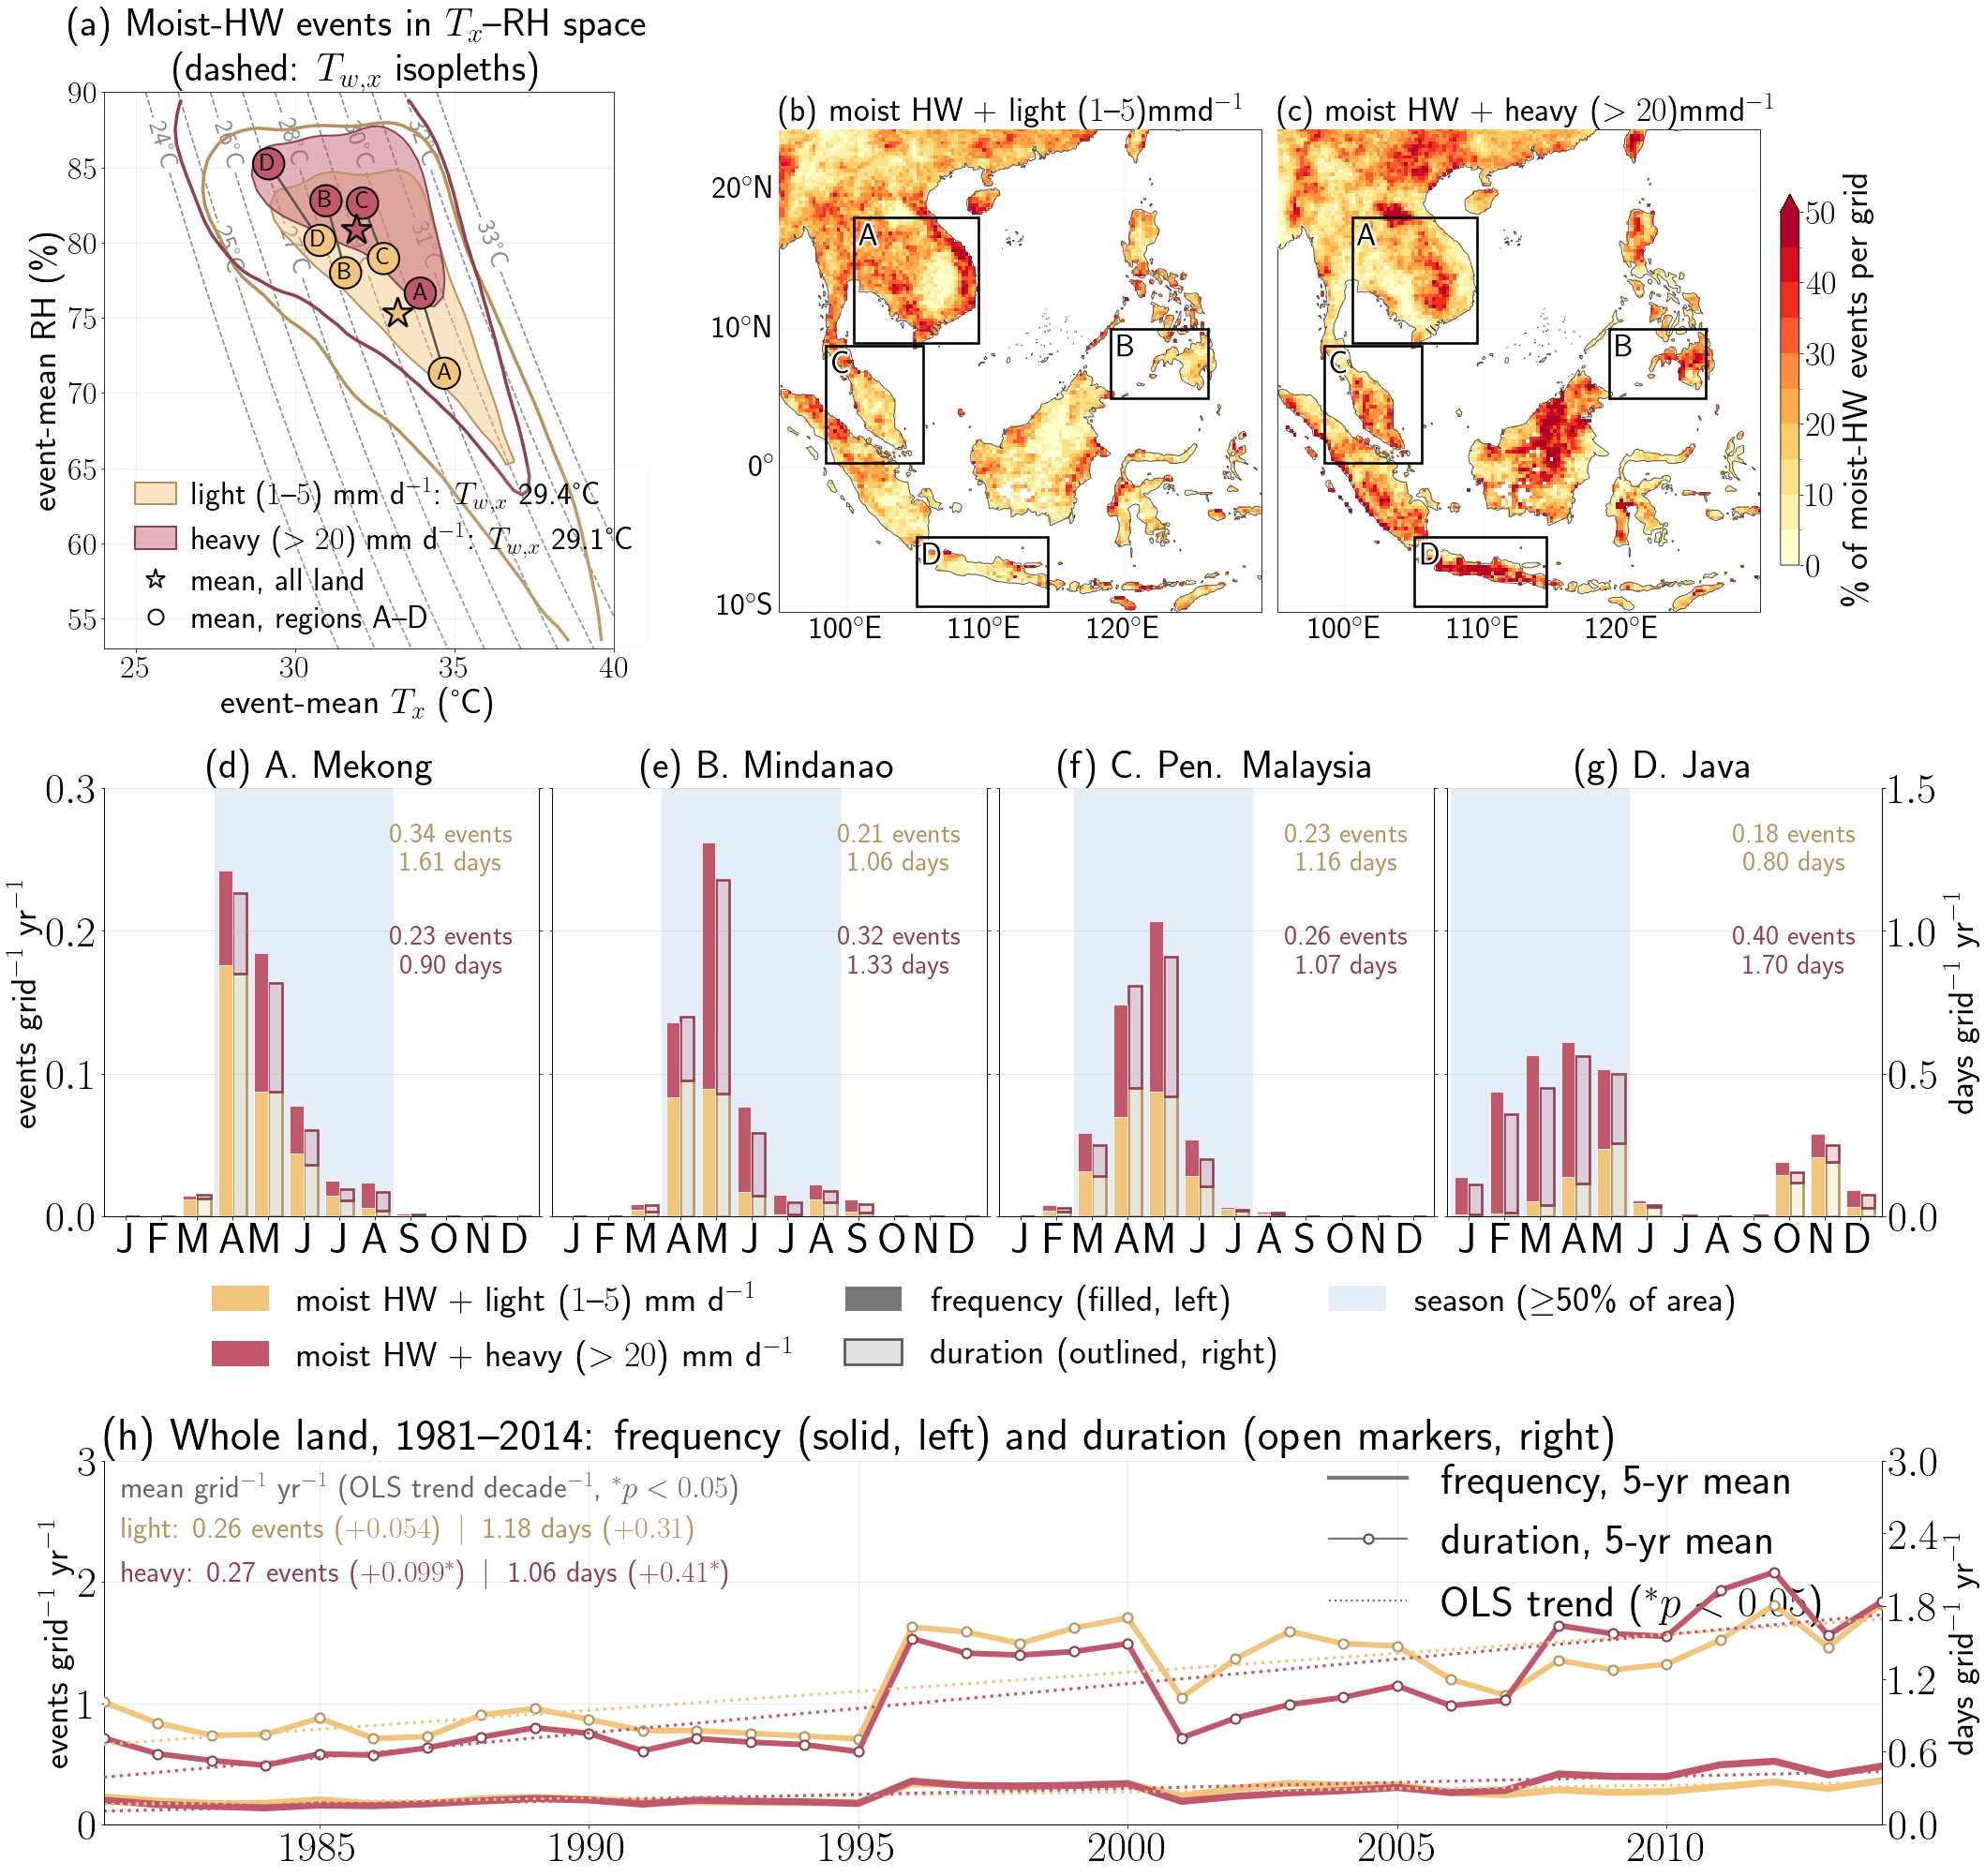

[  0.7 min] TOTAL


In [2]:
# ===== FIGURE 2 (Fig02_observed) | OBS land-only | (a) Tx-RH space, T_wx isopleths | (b,c) maps YlOrRd 0-0.9 | (d-g) seasonal cycle | (h) trend | gaps row1-2 and row2-3 in cm =====
import os, glob, time, gc, warnings, numpy as np, pandas as pd, xarray as xr
import matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.colors as mcolors, matplotlib.patheffects as pe_
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from scipy.stats import linregress
from scipy.ndimage import gaussian_filter
warnings.filterwarnings('ignore')
try:
    import cartopy.crs as ccrs, cartopy.feature as cf, cartopy.io.shapereader as shpr
    from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
    PC = ccrs.PlateCarree()
except Exception: ccrs = None
T0 = time.time(); tk = lambda s_: print(f'[{(time.time()-T0)/60:5.1f} min] {s_}', flush=True)
# ---------------------------- CONFIG ----------------------------
OBSF = {'tasmax': r"D:/G_data/obs-SEA/SEA-mswx-tasmax-1981-end2014.nc", 'hurs': r"D:/G_data/obs-SEA/SEA-mswx-rh-1981-end2014.nc", 'pr': r"D:/G_data/obs-SEA/SEA-mswep-pr-1981-end2014.nc"}
ISP = r"D:/G_data/paper-SRDRN/islands/islands"                                   # VN islands shapefile (folder or .shp)
OUTD, FNAME, DPI, SAVE = r"D:/G_data/paper-SRDRN/fig-ver3methods", 'Fig02_observed', 300, True
CAL, FACTOR, LANDONLY, LANDRES = ('1981-01-01','2014-12-31'), 4, True, '50m'
NM, PQ, MINLEN = 5, 90, 3
RBIN = [1., 5., 20.]
L, MINEV = 3, 20
JSHOW, SFRAC = [1, 3], 0.50
SENS, NMLIST, COVER = True, [3, 4, 5, 6], 0.90
USETEX, FS, FSL = True, 46, 38
CSTEP, CTICK, SM3 = 5., 10., 5                                                  # running mean: 5 (or 3) years
YSC = 'ratio'                                                                    # row-3 axes: 'ratio' | 'same' | 'free'
PALS = {'honey-rose': ('#F2C57C', '#C0576B'), 'apricot-plum': ('#F4A259', '#8E6C9E'), 'butter-berry': ('#F3D17A', '#A4507A'),
        'peach-leaf': ('#F6BD8B', '#6A994E'), 'sand-moss': ('#E8C39E', '#7A8F5A'), 'apricot-teal': ('#F4B183', '#4A9A8C')}
PAL = 'honey-rose'
RL = ['dry ($<1$)', 'light ($1$--$5$)', 'mod ($5$--$20$)', 'heavy ($>20$)']; RLP = ['dry', 'light', 'mod', 'heavy']
RC = ['#bdbdbd', PALS[PAL][0], '#b8a9c9', PALS[PAL][1]]
EC = lambda c_: tuple(np.array(mcolors.to_rgb(c_))*.75)                         # darker edge / text of the same hue
FA, ELW = .22, 2.6                                                               # duration bars: fill alpha | edge width
MCM, MAPCM, MAPTR, SBAND = 'Spectral', 'YlOrRd', (0., .9), '#e3eef8'           # (b,c) warm colormap, only 0-0.9 of its range (avoid the darkest reds)
GAP12_CM, GAP23_CM = 1.0, 1.0                                                    # extra gap (cm) row 1 (a-c) -> row 2 (d-g) and row 2 -> row 3 (h)
BOXES = {'A Mekong': dict(lon=(100.5,109.5), lat=(9.0,18.0)), 'B Mindanao': dict(lon=(119.0,126.0), lat=(5.0,10.0)),
         'C Pen. Malaysia': dict(lon=(98.5,105.5), lat=(0.3,8.8)), 'D Java': dict(lon=(105.0,114.5), lat=(-10.0,-5.0))}
MN = ['J','F','M','A','M','J','J','A','S','O','N','D']; MFULL = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
# ---------------------------- LaTeX ----------------------------
if USETEX:
    try:
        plt.rcParams.update({'text.usetex': True}); _f = plt.figure(); _f.text(.5, .5, r'$T_{w,x}\ 50\%$'); _f.canvas.draw(); plt.close(_f); print('LaTeX rendering: ON')
    except Exception as e:
        USETEX = False; plt.rcParams.update({'text.usetex': False, 'font.family': 'DejaVu Sans'}); print(f'LaTeX not available ({type(e).__name__}) -> mathtext fallback', flush=True)
else: plt.rcParams.update({'text.usetex': False})
PCT_ = r'\%' if USETEX else '%'; DEG = r'$^{\circ}$'
# ---------------------------- 0. READ OBS + LAND MASK ----------------------------
def std_(ds):
    ren = {a:b for a,b in [('latitude','lat'),('longitude','lon'),('Latitude','lat'),('Longitude','lon')] if a in ds.dims or a in ds.coords}
    ds = ds.rename(ren) if ren else ds
    if ds.lat.size>1 and float(ds.lat[0])>float(ds.lat[-1]): ds = ds.sortby('lat')
    if float(ds.lon.min())<0: ds = ds.assign_coords(lon=(ds.lon%360)).sortby('lon')
    return ds
NL = lambda d: d if d.time.dt.calendar=='noleap' else d.convert_calendar('noleap', align_on='year' if d.time.dt.calendar=='360_day' else 'date')
def fx(da, v):
    u = str(da.attrs.get('units','')).lower().replace(' ','')
    if v=='tasmax' and (u in ('k','kelvin') or float(da.isel(time=slice(0,366)).min())>100): da = da-273.15
    if v=='pr':
        mm = float(da.isel(time=slice(0,366)).max())
        if u in ('kgm-2s-1','kg/m2/s') or (0<mm<0.01): da = da*86400.
    return da
def landgrid(la, lo):
    import shapely.geometry as sgeom
    from shapely.prepared import prep
    from shapely.ops import unary_union
    g = unary_union(list(shpr.Reader(shpr.natural_earth(resolution=LANDRES, category='physical', name='land')).geometries()))
    pl = prep(g); x = ((np.asarray(lo)+180.) % 360.) - 180.; X, Y = np.meshgrid(x, np.asarray(la))
    return np.fromiter((pl.contains(sgeom.Point(a,b)) for a,b in zip(X.ravel(), Y.ravel())), bool, X.size).reshape(X.shape)
OKEY_ = (tuple(OBSF.values()), CAL, FACTOR, LANDONLY, LANDRES)
if globals().get('_FN_OBSC') != OKEY_:
    for _v in ['tx','rh','pr','TW','VI','YR','MO','LA','LO','H_','W_']: globals().pop(_v, None)
    gc.collect(); tk('reading OBS'); BIG = {}; tt = None
    for v in ['tasmax','hurs','pr']:
        d = std_(xr.open_dataset(OBSF[v])); vn = v if v in d.data_vars else list(d.data_vars)[0]
        a = fx(NL(d[vn].sel(time=slice(*CAL)).astype('float32').load()), v)
        ny = (a.sizes['lat']//FACTOR)*FACTOR; nx = (a.sizes['lon']//FACTOR)*FACTOR; a = a.isel(lat=slice(0,ny), lon=slice(0,nx)).transpose('time','lat','lon')
        if tt is None: tt = a.time.values.copy(); LA = a.lat.values.astype('f8'); LO = a.lon.values.astype('f8'); H_, W_ = ny, nx
        BIG[v] = a.values.reshape(a.sizes['time'], -1); d.close(); del a; gc.collect()
    VAL = np.ones(H_*W_, bool)
    for v in BIG: VAL &= np.isfinite(BIG[v]).all(0)
    nfin = int(VAL.sum())
    if LANDONLY:
        try: LG = landgrid(LA, LO); VAL &= LG.ravel(); tk(f'land mask NE-{LANDRES}: {int(LG.sum())} land cells / {H_*W_}')
        except Exception as e: print(f'   !! land mask failed ({type(e).__name__}) -> KEEPING OCEAN', flush=True)
    VI = np.flatnonzero(VAL)
    tx = np.ascontiguousarray(BIG['tasmax'][:, VI].T); rh = np.ascontiguousarray(BIG['hurs'][:, VI].T); pr = np.ascontiguousarray(BIG['pr'][:, VI].T); del BIG; gc.collect()
    try: ti = xr.CFTimeIndex(np.asarray(tt))
    except Exception: ti = pd.DatetimeIndex(np.asarray(tt))
    YR = np.asarray(ti.year,'i4'); MO = np.asarray(ti.month,'i4'); _FN_OBSC = OKEY_
    print(f'   finite in all 3 variables: {nfin} cells -> after land mask: {VI.size} cells', flush=True)
n, T = tx.shape; YRU = np.unique(YR); NYR = YRU.size; M0 = MO - 1
LAc = np.broadcast_to(LA[:,None], (H_,W_)).ravel()[VI].astype('f8'); LOc = np.broadcast_to(LO[None,:], (H_,W_)).ravel()[VI].astype('f8'); WL = np.cos(np.radians(LAc))
unflat = lambda z: (lambda o: (o.__setitem__(VI, z), o.reshape(H_,W_))[1])(np.full(H_*W_, np.nan,'f4'))
BM = {k: (LOc>=v['lon'][0]) & (LOc<=v['lon'][1]) & (LAc>=v['lat'][0]) & (LAc<=v['lat'][1]) for k,v in BOXES.items()}
print(f'grid {H_}x{W_} | n = {n} LAND cells | T = {T} days ({NYR} yr)'); print('land cells per box: ' + ' | '.join(f'{k} {int(v.sum())}' for k,v in BM.items()), flush=True)
def stull(Tc, R):
    R = np.clip(R, 5., 99.5)
    return (Tc*np.arctan(0.151977*np.sqrt(R+8.313659)) + np.arctan(Tc+R) - np.arctan(R-1.676331) + 0.00391838*R**1.5*np.arctan(0.023101*R) - 4.686035).astype('f4')
if 'TW' not in globals() or TW.shape != tx.shape:
    TW = np.empty_like(tx)
    for i in range(0, n, 500): TW[i:i+500] = stull(tx[i:i+500], rh[i:i+500])
    tk('Tw_x done')
MTW = np.stack([TW[:, M0 == m].mean(1) for m in range(12)], 1)
# ---------------------------- 1. PER-CELL SEASON ----------------------------
def season(nm):
    cs_ = np.concatenate([MTW, MTW[:, :nm-1]], 1); w_ = np.stack([cs_[:, i:i+nm].mean(1) for i in range(12)], 1)
    ms_ = w_.argmax(1).astype('i1'); ins = np.zeros((n, 12), bool)
    for i in range(n): ins[i, (ms_[i] + np.arange(nm)) % 12] = True
    return ms_, ins[np.arange(n)[:, None], M0[None, :]], ins
def detect(sd_):
    q_ = np.array([np.percentile(TW[i, sd_[i]], PQ) for i in range(n)], 'f4'); rw = (TW > q_[:, None]) & sd_
    dd = np.diff(np.pad(rw.astype(np.int8), ((0,0),(1,1))), axis=1)
    cc, ss = np.nonzero(dd == 1); _, ee = np.nonzero(dd == -1); d2 = ee - ss; k2 = d2 >= MINLEN
    Gc = np.cumsum((dd[:, :-1] == 1).ravel(), dtype='i4').reshape(rw.shape); del dd
    mp_ = np.full(cc.size + 1, -1, 'i4'); mp_[1:][k2] = np.arange(int(k2.sum())); hw = (mp_[Gc] >= 0) & rw; del Gc, rw; gc.collect()
    return q_, hw, cc[k2], ss[k2], d2[k2]
def wincls(cc, ss):
    mx_ = np.full(cc.size, -1., 'f4')
    for k in range(-L, L+1): t = ss + k; ok = (t >= 0) & (t < T); mx_[ok] = np.maximum(mx_[ok], pr[cc[ok], t[ok]])
    return np.digitize(mx_, RBIN).astype('i1')
def shortrun(p):
    for ln in range(1, 13):
        for st in range(12):
            ix = [(st+k) % 12 for k in range(ln)]
            if p[ix].sum() >= COVER: return ln, ix
    return 12, list(range(12))
mst, SEASD, INSEA = season(NM)
bc = np.bincount(mst, minlength=12); pfr = bc/n; RLEN, RUN = shortrun(pfr)
sfrac = lambda k: (WL[k][:, None]*INSEA[k]).sum(0)/max(WL[k].sum(), 1e-9); SF = {k: sfrac(v) for k, v in BM.items()}
def band(f): b = np.flatnonzero(f >= SFRAC); return b if b.size else np.argsort(-f)[:NM]
print(f'\nseason = {NM} months PER CELL | onset: ' + ' '.join(f'{MFULL[m]} {100*pfr[m]:.0f}%' for m in np.argsort(-bc)[:6]))
print(f'>> shortest consecutive run covering {COVER*100:.0f}% of cells: {"-".join(MFULL[m] for m in RUN)} = {100*pfr[RUN].sum():.1f}%')
for k in BM: print(f'   {k:16s} season = {"-".join(MFULL[m] for m in band(SF[k]))}')
# ---------------------------- 2. DETECTION ----------------------------
QW, MHWd, c, s, du = detect(SEASD); en = s + du - 1; NE = c.size
ECLS = wincls(c, s); MOS = M0[s]; YRS_ = YR[s] - YRU[0]
print(f'\nq{PQ} Tw_x: mean {QW.mean():.2f} degC | {NE} events ({NE/n/NYR:.2f}/cell/yr) | D {du.mean():.2f} d | {MHWd.sum()/n/NYR:.2f} d/cell/yr | {100*MHWd.sum()/SEASD.sum():.2f}% of in-season days', flush=True)
if SENS:
    print('\n--- SENSITIVITY to season length NM ---'); print(f'{"NM":>3s} {"q90 Tw":>8s} {"ev/cell/yr":>11s} {"d/cell/yr":>10s} {"D":>6s} {"%light":>7s} {"%heavy":>7s} {"90% run":>8s}')
    for nm_ in NMLIST:
        ms2, sd2, in2 = season(nm_); r2, _ = shortrun(np.bincount(ms2, minlength=12)/n); q2, hw2, c2, s2, d2 = detect(sd2); e2 = wincls(c2, s2); w2 = WL[c2]
        print(f'{nm_:3d} {q2.mean():8.2f} {c2.size/n/NYR:11.2f} {d2.sum()/n/NYR:10.2f} {d2.mean():6.2f} {100*(w2*(e2==1)).sum()/w2.sum():7.1f} {100*(w2*(e2==3)).sum()/w2.sum():7.1f} {r2:6d} mo')
        del ms2, sd2, in2, q2, hw2, c2, s2, d2, e2; gc.collect()
    tk('sensitivity done')
# ---------------------------- 3. FREQUENCY (events) + DURATION (HW days), ONE class per event ----------------------------
IXM = c*48 + MOS*4 + ECLS; IXY = c*(NYR*4) + YRS_*4 + ECLS
CNM = np.bincount(IXM, minlength=n*48).reshape(n, 12, 4).astype('f4'); DNM = np.bincount(IXM, weights=du, minlength=n*48).reshape(n, 12, 4).astype('f4')
CNY = np.bincount(IXY, minlength=n*NYR*4).reshape(n, NYR, 4).astype('f4'); DNY = np.bincount(IXY, weights=du, minlength=n*NYR*4).reshape(n, NYR, 4).astype('f4'); del IXM, IXY
rate = lambda A, k: (WL[k][:,None,None]*A[k]).sum(0)/max(WL[k].sum(), 1e-9); ALLM = np.ones(n, bool)
MEd, MDd = rate(CNM, ALLM)/NYR, rate(DNM, ALLM)/NYR; MEr = {k: rate(CNM, v)/NYR for k, v in BM.items()}; MDr = {k: rate(DNM, v)/NYR for k, v in BM.items()}
AEd, ADd = rate(CNY, ALLM), rate(DNY, ALLM); AEr = {k: rate(CNY, v) for k, v in BM.items()}; ADr = {k: rate(DNY, v) for k, v in BM.items()}
ULE, ULD = r'events grid$^{-1}$ yr$^{-1}$', r'days grid$^{-1}$ yr$^{-1}$'
print('\nFREQUENCY (ev/grid/yr) | DURATION (d/grid/yr) | mean D (d/event), by event rain class, cos-lat weighted:')
print(f'{"region":18s} ' + ' '.join(f'{RLP[j]+" ev":>9s} {RLP[j]+" d":>9s} {RLP[j]+" D":>9s}' for j in JSHOW))
for k in list(BM) + ['WHOLE LAND']:
    E_, D_ = (MEd, MDd) if k == 'WHOLE LAND' else (MEr[k], MDr[k])
    print(f'{k:18s} ' + ' '.join(f'{E_[:,j].sum():9.3f} {D_[:,j].sum():9.3f} {D_[:,j].sum()/max(E_[:,j].sum(),1e-9):9.2f}' for j in JSHOW))
# ---------------------------- 4. EVENT CLASS over onset +- L (maps) ----------------------------
nev = np.bincount(c, minlength=n); PCT = np.full((n, 4), np.nan, 'f4')
for j in range(4): PCT[:, j] = 100.*np.bincount(c[ECLS == j], minlength=n)/np.maximum(nev, 1)
PCT[nev < MINEV] = np.nan
fdom = np.array([100.*(WL[c]*(ECLS == j)).sum()/WL[c].sum() for j in range(4)])
print(f'\n% of EVENTS by rain class (max P over onset+-{L}, fixed {2*L+1}-day window):  ' + '  '.join(f'{RLP[j]} {fdom[j]:.1f}' for j in range(4)))
# ---------------------------- 5. TRENDS + AXIS LIMITS ----------------------------
def trend(y):
    m = np.isfinite(y)
    if m.sum() < 10: return np.nan, np.nan, np.nan
    r = linregress(YRU[m].astype('f8'), y[m]); return r.slope*10., r.pvalue, r.intercept
fmt = lambda y: (lambda t: f'{t[0]:+7.3f}{"*" if t[1] < .05 else " "}(p{t[1]:4.2f})')(trend(y))
print(f'\ntrend {YRU[0]}-{YRU[-1]} per DECADE (OLS; * p<0.05)  [ev = events/grid | d = days/grid]:'); print(f'{"region":18s} ' + ' '.join(f'{RLP[j]+" ev":>17s} {RLP[j]+" d":>17s}' for j in JSHOW))
for k in list(BM) + ['WHOLE LAND']:
    E_, D_ = (AEd, ADd) if k == 'WHOLE LAND' else (AEr[k], ADr[k])
    print(f'{k:18s} ' + ' '.join(f'{fmt(E_[:,j]):>17s} {fmt(D_[:,j]):>17s}' for j in JSHOW))
print('   OLS ignores year-to-year autocorrelation; use Mann-Kendall + Yue-Pilon for the final table')
rm3 = lambda a, w=SM3: (lambda v, kk: np.where(np.convolve(v.astype(float), kk, 'same') >= max(2, w//2+1), np.convolve(np.where(v, a, 0.), kk, 'same')/np.maximum(np.convolve(v.astype(float), kk, 'same'), 1e-9), np.nan))(np.isfinite(a), np.ones(w))
nice = lambda v: (lambda st: st*np.ceil(v/st))(10**np.floor(np.log10(max(v, 1e-9)))/2)
YE = nice(max(MEr[k][:, JSHOW].sum(1).max() for k in BM)); YD = nice(max(MDr[k][:, JSHOW].sum(1).max() for k in BM))
DBAR = ADd[:, JSHOW].sum()/max(AEd[:, JSHOW].sum(), 1e-9)
tk('computation done')
# ---------------------------- 6. EVENT MEANS (Tx, RH, Tw) for light/heavy + 2D density ----------------------------
NG = PCT.shape[0]; JL, JH = JSHOW
lst = en - 1 if np.all(en - s == du) else en; dd = (lst - s + 1).astype('f8')
mk = (ECLS == JL) | (ECLS == JH); ce, se_, le, de, ke = c[mk], s[mk], lst[mk], dd[mk], ECLS[mk]
def evmean(X):                                                                   # per-event mean via cumsum, no day x event array
    cs = np.cumsum(X, axis=1, dtype='f8'); r = (cs[ce, le] - np.where(se_ > 0, cs[ce, np.maximum(se_-1, 0)], 0.))/de; del cs; return r
ETX, ERH, ETW = evmean(tx), evmean(rh), evmean(TW); tk('event means')
for j in JSHOW: q = ke == j; print(f'{RLP[j]:<8} n={q.sum():>6,} | Tx {np.median(ETX[q]):.1f} degC | RH {np.median(ERH[q]):.0f}% | Tw {np.median(ETW[q]):.1f} degC')
stull_iso = lambda T_, R: T_*np.arctan(.151977*np.sqrt(R+8.313659)) + np.arctan(T_+R) - np.arctan(R-1.676331) + .00391838*R**1.5*np.arctan(.023101*R) - 4.686035
XB = np.arange(np.floor(np.percentile(ETX, .5)), np.ceil(np.percentile(ETX, 99.5))+.25, .25)
YB = np.arange(np.floor(np.percentile(ERH, .5)), min(100., np.ceil(np.percentile(ERH, 99.5)))+1., 1.)
def hdr(x, y, fr=(.9, .5)):                                                      # smoothed 2D density + levels enclosing 90% / 50% of events
    Hh, _, _ = np.histogram2d(x, y, [XB, YB]); Hh = gaussian_filter(Hh.T, 1.5); Hh /= Hh.sum()
    hs = np.sort(Hh.ravel())[::-1]; cs = np.cumsum(hs); return Hh, [hs[np.searchsorted(cs, f)] for f in fr]
DEN = {j: hdr(ETX[ke == j], ERH[ke == j]) for j in JSHOW}
IDX = unflat(np.arange(NG, dtype='f8')); okc = np.isfinite(IDX)
def rcell(k):                                                                    # region mask on the NG land cells
    m = np.asarray(BM[k]).astype(bool)
    if m.size == NG: return m.ravel()
    r = np.zeros(NG, bool); r[IDX[okc].astype(int)] = m.reshape(H_, W_)[okc]; return r
RMK = {k: rcell(k)[ce] for k in BM}
# ---------------------------- 7. VN ISLANDS SHAPEFILE ----------------------------
def load_isl(p):
    fs = sorted(glob.glob(os.path.join(p, '**', '*.shp'), recursive=True)) if os.path.isdir(p) else [p if p.lower().endswith('.shp') else p + '.shp']; G = []
    for f in fs:
        try:
            import geopandas as gpd; d = gpd.read_file(f)
            if d.crs is not None and d.crs.to_epsg() != 4326: d = d.to_crs(4326)
            G += [g for g in d.geometry if g is not None and not g.is_empty]
        except ImportError: G += [g for g in shpr.Reader(f).geometries() if g is not None and not g.is_empty]
    print(f'islands: {len(fs)} shp, {len(G)} geometries', flush=True); return G
ISL = (globals().get('ISL') or load_isl(ISP)) if ccrs else []
ISL_P = [g for g in ISL if g.geom_type not in ('Point', 'MultiPoint')]
ISL_XY = np.array([(q.x, q.y) for g in ISL if g.geom_type in ('Point', 'MultiPoint') for q in (g.geoms if g.geom_type == 'MultiPoint' else [g])]).reshape(-1, 2)
# ======================== FIGURE ========================
plt.rcParams.update({'font.size': FS, 'axes.titlesize': FS+2, 'axes.labelsize': FSL, 'xtick.labelsize': FS, 'ytick.labelsize': FS, 'legend.fontsize': FS})
FS, FSL = 34, 38
PRJ = {'projection': PC} if ccrs else {}; TR = {'transform': PC} if ccrs else {}; HALO = [pe_.withStroke(linewidth=5, foreground='white')]
RNAME = lambda k: k.split()[0] + '. ' + ' '.join(k.split()[1:])
def deco(a, ttl, left=True):                                                     # coastline + VN islands only (no country borders)
    a.set_facecolor('white')
    if ccrs:
        a.add_feature(cf.OCEAN, facecolor='white', zorder=1); a.coastlines(lw=.9, color='#444444', zorder=8)
        if ISL_P: a.add_geometries(ISL_P, crs=PC, facecolor='none', edgecolor='#444444', linewidth=.9, zorder=8)
        if ISL_XY.size: a.scatter(ISL_XY[:, 0], ISL_XY[:, 1], s=4, c='#444444', transform=PC, zorder=8)
        a.set_extent([LO.min(), LO.max(), LA.min(), LA.max()], crs=PC)
        gl = a.gridlines(draw_labels=True, lw=.4, color='#dddddd', xlocs=np.arange(100, 131, 10), ylocs=np.arange(-10, 25, 10))
        gl.top_labels = gl.right_labels = False; gl.left_labels = left
        gl.xformatter = LongitudeFormatter(degree_symbol=DEG); gl.yformatter = LatitudeFormatter(degree_symbol=DEG); gl.xlabel_style = gl.ylabel_style = {'size': FS}
    for k, v in BOXES.items():
        a.add_patch(Rectangle((v['lon'][0], v['lat'][0]), v['lon'][1]-v['lon'][0], v['lat'][1]-v['lat'][0], fill=False, ec='k', lw=2.6, zorder=9, **TR))
        a.text(v['lon'][0]+.3, v['lat'][1]-.4, k.split()[0], color='k', fontsize=FS, fontweight='bold', va='top', zorder=10, path_effects=HALO, **TR)
    a.set_title(ttl, fontsize=FS+2, loc='left', pad=8)
FH = 30.; fig = plt.figure(figsize=(34, FH)); gs = fig.add_gridspec(3, 24, hspace=.2, wspace=.2, height_ratios=[1.30, 1.0, 0.85])
AE = AD = 3.; YSC = 'same'
# ---- (a) Tx-RH space of light vs heavy moist-HW events, Tw,x isopleths
a0 = fig.add_subplot(gs[0, 0:7]); XC, YC = (XB[:-1]+XB[1:])/2, (YB[:-1]+YB[1:])/2
TXg, RHg = np.meshgrid(np.linspace(XB[0], XB[-1], 200), np.linspace(YB[0], YB[-1], 200))
TWL = np.arange(np.floor(np.percentile(ETW, 2)), np.ceil(np.percentile(ETW, 99.5))+1, 1.)
ct = a0.contour(TXg, RHg, stull_iso(TXg, RHg), levels=TWL, colors='#888888', linewidths=1.6, linestyles='--', zorder=1); a0.clabel(ct, fmt=lambda v: f'{v:.0f}°C', fontsize=FS-6, inline=True)
a0.set(xlabel=r'event-mean $T_x$ (°C)', ylabel=r'event-mean RH (\%)', xlim=(XB[0], XB[-1]), ylim=(YB[0], YB[-1]))
a0.set_title(r'(a) Moist-HW events in $T_x$--RH space' + '\n' + r'(dashed: $T_{w,x}$ isopleths)', fontsize=FS+8)
a0.tick_params(labelsize=FS); a0.xaxis.label.set_size(FSL); a0.yaxis.label.set_size(FSL); a0.grid(alpha=.25, zorder=0); MU = {}
for j in JSHOW:
    Hh, (l90, l50) = DEN[j]; q = ke == j
    a0.contourf(XC, YC, Hh, levels=[l50, Hh.max()*1.01], colors=[mcolors.to_rgba(RC[j], .45)], zorder=3)
    a0.contour(XC, YC, Hh, levels=[l90], colors=[EC(RC[j])], linewidths=3.5, zorder=4); a0.contour(XC, YC, Hh, levels=[l50], colors=[EC(RC[j])], linewidths=2, zorder=4)
    a0.plot(ETX[q].mean(), ERH[q].mean(), '*', ms=34, mfc=RC[j], mec='k', mew=2.5, zorder=8)
    for k in BM: qk = q & RMK[k]; MU[j, k] = (ETX[qk].mean(), ERH[qk].mean())
for k in BM:
    a0.plot(*zip(MU[JL, k], MU[JH, k]), color='#555555', lw=2.5, zorder=5)
    for j in JSHOW: a0.text(*MU[j, k], k.split()[0], ha='center', va='center', fontsize=FS-8, fontweight='bold', color='k', bbox=dict(boxstyle='circle,pad=.2', fc=RC[j], ec='k', lw=2), zorder=7)
a0.legend(handles=[Patch(fc=mcolors.to_rgba(RC[j], .45), ec=EC(RC[j]), lw=2, label=f'{RL[j]} mm d$^{{-1}}$: $T_{{w,x}}$ {ETW[ke == j].mean():.1f}°C') for j in JSHOW]
          + [Line2D([], [], ls='none', marker='*', ms=22, mfc='w', mec='k', mew=2, label='mean, all land'), Line2D([], [], ls='none', marker='o', ms=16, mfc='w', mec='k', mew=2, label='mean, regions A--D')],
          loc='lower left', bbox_to_anchor=(0.01, -0.02), fontsize=FS, frameon=True, framealpha=.1, handlelength=1.3, handletextpad=.5, labelspacing=.3, borderpad=.4, borderaxespad=.4)
# ---- (b,c) maps: % of moist-HW events per class
VMX = CSTEP*np.ceil(np.nanpercentile(PCT[:, JSHOW], 98)/CSTEP)
LEV = np.arange(0., VMX+CSTEP, CSTEP); CM = mcolors.ListedColormap(plt.get_cmap(MAPCM)(np.linspace(*MAPTR, LEV.size-1))); NRM = mcolors.BoundaryNorm(LEV, LEV.size-1); AX = []
for i, j in enumerate(JSHOW):
    a = fig.add_subplot(gs[0, 9+7*i:16+7*i], **PRJ); AX.append(a)
    h = a.pcolormesh(LO, LA, unflat(PCT[:, j]), cmap=CM, norm=NRM, shading='auto', zorder=3, **TR); deco(a, f'({"bc"[i]}) moist HW $+$ {RL[j]}mmd$^{{-1}}$', left=(i == 0))
cb = fig.colorbar(h, ax=AX, fraction=.026, pad=.02, shrink=.7, ticks=np.arange(0., VMX+CTICK, CTICK), extend='max'); cb.set_label(f'{PCT_} of moist-HW events per grid', fontsize=FSL); cb.ax.tick_params(labelsize=FS+2)
# ---- (d-g) seasonal cycle per region
x = np.arange(12); AXD = []; BXD = []; BW = .38
for i, k in enumerate(BM):
    a = fig.add_subplot(gs[1, 6*i:6*i+6]); b = a.twinx(); AXD.append(a); BXD.append(b)
    for m in band(SF[k]): b.axvspan(m-.5, m+.5, color=SBAND, zorder=0)
    be, bd = np.zeros(12), np.zeros(12)
    for j in JSHOW:
        a.bar(x-.2, MEr[k][:, j], BW, bottom=be, color=RC[j], ec='white', lw=.8, zorder=3); be += MEr[k][:, j]
        b.bar(x+.2, MDr[k][:, j], BW, bottom=bd, fc=mcolors.to_rgba(RC[j], FA), ec=EC(RC[j]), lw=ELW, zorder=3); bd += MDr[k][:, j]
    a.set_zorder(b.get_zorder()+1); a.patch.set_visible(False); a.set(xticks=x, xticklabels=MN, xlim=(-.6, 11.6), ylim=(0., YE)); b.set_ylim(0., YD)
    a.set_title(f'({"defg"[i]}) {RNAME(k)}', fontsize=FS+8)
    for jj, j in enumerate(JSHOW): a.text(.8, .92 - .24*jj, f'{MEr[k][:, j].sum():.2f} events' + '\n' + f'{MDr[k][:, j].sum():.2f} days', transform=a.transAxes, ha='center', va='top', fontsize=FS-4, color=EC(RC[j]), fontweight='bold', zorder=20)
    a.grid(axis='y', alpha=.35, zorder=1); a.spines['top'].set_visible(False); b.spines['top'].set_visible(False)
    if i == 0: a.set_ylabel(ULE, fontsize=FSL)
    else: a.set_yticklabels([])
    if i == len(BM)-1: b.set_ylabel(ULD, fontsize=FSL)
    else: b.set_yticklabels([])
AXD[0].legend(handles=[Patch(fc=RC[j], ec='none', label=f'moist HW $+$ {RL[j]} mm d$^{{-1}}$') for j in JSHOW]
                      + [Patch(fc='#777777', ec='white', label='frequency (filled, left)'), Patch(fc=mcolors.to_rgba('#777777', FA), ec='#555555', lw=ELW, label='duration (outlined, right)'),
                         Patch(fc=SBAND, ec='none', label=f'season ($\\geq${SFRAC*100:.0f}{PCT_} of area)')],
              loc='upper center', bbox_to_anchor=(2, -0.12), ncol=3, fontsize=FSL, frameon=False, handlelength=1.6, columnspacing=1.4, borderaxespad=0.)
# ---- (h) whole-land time series + trend
aT = fig.add_subplot(gs[2, 0:24]); bT = aT.twinx()
aT.text(.01, .97, r'mean grid$^{-1}$ yr$^{-1}$ (OLS trend decade$^{-1}$, $^{*}p<0.05$)', transform=aT.transAxes, fontsize=FS-1, color='#666666', va='top')
for ii, j in enumerate(JSHOW):
    aT.plot(YRU, rm3(AEd[:, j]), lw=7.5, color=RC[j], zorder=6); bT.plot(YRU, rm3(ADd[:, j]), lw=6, color=RC[j], marker='o', ms=10, mfc='white', mec=EC(RC[j]), mew=2.2, zorder=6)
    se, pe, ie = trend(AEd[:, j]); sd, pd_, id_ = trend(ADd[:, j])
    aT.plot(YRU, ie + se/10.*YRU.astype('f8'), lw=3.2, ls=':', color=RC[j], zorder=7); bT.plot(YRU, id_ + sd/10.*YRU.astype('f8'), lw=3.2, ls=':', color=RC[j], zorder=7)
    aT.text(.01, .85 - .12*ii, f'{RLP[j]}:  {np.nanmean(AEd[:, j]):.2f} events (${se:+.3f}$' + (r'$^{*}$' if pe < .05 else '') + ')' + r'$\;\;|\;\;$' + f'{np.nanmean(ADd[:, j]):.2f} days (${sd:+.2f}$' + (r'$^{*}$' if pd_ < .05 else '') + ')',
            transform=aT.transAxes, fontsize=FS-2, color=EC(RC[j]), va='top', fontweight='bold')
aT.set(xlim=(YRU[0], YRU[-1]), ylim=(0., AE), ylabel=ULE); bT.set_ylim(0., AD)
bT.set_ylabel(ULD + ('\n' + rf'(= left $\times$ {DBAR:.1f} d event$^{{-1}}$)' if YSC == 'ratio' else ''), fontsize=FSL); bT.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
aT.set_title(r'(h) Whole land, ' + f'{YRU[0]}--{YRU[-1]}' + r': frequency (solid, left) and duration (open markers, right)', loc='left')
aT.grid(alpha=.3, zorder=1); aT.spines['top'].set_visible(False); bT.spines['top'].set_visible(False)
aT.legend(handles=[Line2D([], [], color='#777777', lw=4.2, label=f'frequency, {SM3}-yr mean'), Line2D([], [], color='#777777', lw=2.2, marker='o', ms=10, mfc='white', mec='#555555', mew=2.2, label=f'duration, {SM3}-yr mean'),
                   Line2D([], [], color='#777777', lw=2.2, ls=':', label=r'OLS trend ($^{*}p<0.05$)')], loc='upper right', bbox_to_anchor=(0.99, 1.1), ncol=1, frameon=False, handlelength=1.8, columnspacing=1.6)
# ---- exact gaps: measure the drawn rows, then move row 2 and row 3 (only parent axes; twinx axes follow)
fig.tight_layout(rect=[0, .07, 1, .99]); fig.canvas.draw(); RD_ = fig.canvas.get_renderer(); INV_ = fig.transFigure.inverted()
BB_ = lambda o: (o.get_window_extent(RD_) if isinstance(o, mpl.legend.Legend) else o.get_tightbbox(RD_)).transformed(INV_)
YB_ = lambda arts: min(BB_(o).y0 for o in arts); YT_ = lambda arts: max(BB_(o).y1 for o in arts)
def MV_(arts, dy):
    for o in arts: p = o.get_position(); o.set_position([p.x0, p.y0+dy, p.width, p.height])
R1_, R2_, R3_ = [a0] + AX + [cb.ax], AXD + BXD, [aT, bT]; LG2_ = AXD[0].get_legend()
MV_(AXD, YB_(R1_) - GAP12_CM/2.54/FH - YT_(R2_)); fig.canvas.draw()              # row 2 top = GAP12_CM below row 1
MV_([aT], min(YB_(R2_), BB_(LG2_).y0) - GAP23_CM/2.54/FH - YT_(R3_)); fig.canvas.draw()   # row 3 top = GAP23_CM below row 2 and its legend
DH_ = max(0., .01 - YB_(R3_))*FH                                                 # grow the figure downward if row 3 left the canvas
if DH_ > 0:
    FHn_ = FH + DH_; fig.set_figheight(FHn_)
    for o in [a0] + AX + [cb.ax] + AXD + [aT]: p = o.get_position(); o.set_position([p.x0, (p.y0*FH + DH_)/FHn_, p.width, p.height*FH/FHn_])
if SAVE:
    os.makedirs(OUTD, exist_ok=True)
    for ext in ('pdf', 'png'): fig.savefig(os.path.join(OUTD, f'{FNAME}.{ext}'), bbox_inches='tight', dpi=DPI, facecolor='white'); tk(f'saved {FNAME}.{ext}')
plt.show(); plt.close(fig); tk('TOTAL')